# Weather Consistency's Relationship to Mental Health in the US

# Permissions

Place an `X` in the appropriate bracket below to specify if you would like your group's project to be made available to the public. (Note that student names will be included (but PIDs will be scraped from any groups who include their PIDs).

* [  ] YES - make available
* [ X ] NO - keep private

# Names

- Preity Singh
- Lavin Ma
- Katie Ngo
- Thatcher Eames
- Krrish Jain

# Abstract

Please write one to four paragraphs that describe a very brief overview of why you did this, how you did, and the major findings and conclusions.

# Research Question

#### Does seasonal temperature varibiability, which will be measured by the standard deviation from average daily temperatures, help explain differences in location-based mental health metrics, measured by the CDC in the years 2021 and 2022?
Our research will attempt to minimize the influence of confounding variables by accounting for other  impactful statistics on mental health.

##### **Subquestions:** 
- Which factor more closely aligns with happiness levels: average temperature or temperature variability
- Do the top 10 happiest cities experience lower seasonal teperature variability than the bottom 10 least happy cities?
- How does the relationship between temperature variability and happiness differ in citites with higher vs. lower percentages of high-income households?



## Background and Prior Work


The relationship between weather and human well-being has been a topic of interest in environmental research for years, with strong connections to psychological studies. Numerous studies have shown that weather conditions such as sunny days tend to improve mood, while rainy days can increase feelings of sadness. Although these findings are valuable, weather is a complex phenomenon that encompasses a wide range of factors, making it challenging to grasp its direct effects on human well-being. To address this, our research aims to investigate the role of temperature variability within a single day. We will examine whether the fluctuation between daytime high and nighttime low temperatures has a profound effect on a city’s overall happiness. By focusing on temperature variability rather than climate trends, we can more accurately identify patterns that reveal how weather affects happiness levels.

Past research has utilized long-term average temperatures to draw conclusions about the impact of weather on happiness. For example, Rehdanz’s study of climate trends in 67 countries, using mean temperature and precipitation in the hottest and coldest months, found that higher temperatures during the coldest month were associated with greater happiness.<a name="cite_ref-1"></a>[<sup>1</sup>](#cite_note-1) Another study by Tsutsui found that happiness was highest at a maximum temperature of 13.9 Celsius.<a name="cite_ref-2"></a>[<sup>2</sup>](#cite_note-2) However, the results also indicated that although temperature influences people’s happiness, there is considerable variation in their responses. Few studies have explored how day-to-day weather changes, such as shifts between extreme and low temperatures, affect individuals’ happiness. A notable exception is research by Lucas and Lawless, which analyzed data from 1 million Americans over five years, combining different daily weather variables with life satisfaction ratings. They concluded that there was no significant correlation between temperature and life satisfaction judgments.<a name="cite_ref-3"></a>[<sup>3</sup>](#cite_note-3)

**Our work narrows the focus to temperature variability and its relationship with happiness at the city level. Past work has tendened to focus on average temperatures and its relationship to happiness. Does the overall consistency of the weather, consistently hot or cold rather than prone to large fluctutions throughout the year, correlate with overall happiness. Does stability bring contentment and peace?**

This question connects to a broader idea in psychology: the more uncontrolled factors in your life, the more likely they are to impact your mental health. Weather, as an external and often unpredictable force, may function as one of these factors. If we view stability as a source of comfort and predictability, then cities with more stable weather patterns might foster a greater sense of peace and happiness among residents. Constant change, even in something as mundane as temperature, could contribute to stress or discomfort. Does greater stability in the environment support mental well-being? This is the central question our project seeks to explore.

1. <a name="cite_note-1"></a> [^](#cite_ref-1) Rehdanz, Katrin (8 Dec 2004) Climate and Happiness. *Ecological Economics*. https://www.sciencedirect.com/science/article/pii/S0921800904002940 
2. <a name="cite_note-2"></a> [^](#cite_ref-2) Tsutsui, Yoshiro (1 Jan 2013) Weather and Individual Happiness. *Weather, Climate, and Society*. https://journals.ametsoc.org/view/journals/wcas/5/1/wcas-d-11-00052_1.xml 
3. <a name="cite_note-3"></a> [^](#cite_ref-3) Lucas, Richard E. and Lawless, Nicole M. (1 May 2014) Does Life Seem Better on a Sunny Day? *National Library of Medicine*. https://pmc.ncbi.nlm.nih.gov/articles/PMC3695376/

# Hypothesis



Our hypothesis is that cities with greater seasonal temperature variability, measured by the standard deviation of daily temperatures, will result in higher rates of depression and an increase in mental distress among adults.
The thought process here centers on environmental stability, where predictable and consistent weather patterns play a role in psychological stability. Conversely, extreme shifts in temperature reduce our sense of control, disrupt daily routines, and raise stress levels, all of which negatively impact mental health.

# Data

## Data overview

For each dataset include the following information
- Dataset #1
  - Dataset Name: **CDC Mental Health Data**
  - Link to the dataset: https://www.cdc.gov/places/about/index.html
  - Number of observations: 3,592
  - Number of variables: 7
  - Description: The key variables include the location, population count and percentage, and health measure names. We will filter out the two measures: “Depression among adults” and “Frequent mental distress among adults” for our analysis of the years 2021 and 2022.
- Dataset #2
  - Dataset Name: **Carnegie Mellon Temperature and Precipitation Data**
  - Link to the dataset: https://kilthub.cmu.edu/articles/dataset/Compiled_daily_temperature_and_precipitation_data_for_the_U_S_cities/7890488
  - Number of observations: 238,710
  - Number of variables: 8
  - Description: This dataset contains daily weather data for each day starting earlier than year 1900 within 210 U.S. cities. The key variables in this dataset with their respective city names are max/min temperature in Fahrenheit (float), precipitation in inches (float), and data (string). We will use these metrics for daily climate variability by filtering for the years 2021 and 2022, extracting the appropriate month and day, and removing unnecessary columns.

Combining the Datasets: In order to analyze the relationship between temperature variability and mental health outcomes, cities appearing in both datasets were selected for analysis. We matched city name and year to calculate temperature variability using the standard deviation of daily temperatures. Using comparative analysis, we integrated the data with mental health statistics to draw meaningful conclusions.

## CDC Mental Health Data

In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
us_health_data = pd.read_csv('CDC_Place_Health_Data.csv')
print(us_health_data.shape)
print(us_health_data['Measure'].unique())
print(us_health_data['Year'].unique())
print(len(us_health_data['LocationName'].unique()))

(2274860, 22)
['High blood pressure among adults'
 'High cholesterol among adults who have ever been screened'
 'Taking medicine to control high blood pressure among adults with high blood pressure'
 'Cholesterol screening among adults' 'Cognitive disability among adults'
 'Any disability among adults' 'Hearing disability among adults'
 'Independent living disability among adults'
 'Mobility disability among adults' 'Self-care disability among adults'
 'Vision disability among adults' 'Arthritis among adults'
 'Cancer (non-skin) or melanoma among adults'
 'Current asthma among adults' 'Coronary heart disease among adults'
 'Chronic obstructive pulmonary disease among adults'
 'Depression among adults' 'Diagnosed diabetes among adults'
 'Obesity among adults' 'Stroke among adults'
 'All teeth lost among adults aged >=65 years'
 'Fair or poor self-rated health status among adults'
 'Frequent mental distress among adults'
 'Frequent physical distress among adults'
 'Current lack of health

In [3]:
mental_health_data_unclean = us_health_data.loc[us_health_data['Measure'].isin(['Frequent mental distress among adults', 'Depression among adults'])]

## Carnagie Mellon Temperature and Percipitation Data

In [4]:
# Each city has its data in a seperate DataFrame named by an id number. The name & data of each city corresponding to the id is tracked in the dataframe below
ctd_key = pd.read_csv('Historical Weather Data/city_info.csv')

In [5]:
city_temperature_data_unclean = pd.DataFrame()

for ind in ctd_key.index:
    city_name = ctd_key.iloc[ind,1]
    city_id = ctd_key.iloc[ind,2]
    csv_file_name = 'Historical Weather Data/' + city_id + '.csv'
    city_data_frame = pd.read_csv(csv_file_name)
    city_data_frame.insert(loc=0, column='City', value = city_name)
    city_temperature_data_unclean = pd.concat([city_temperature_data_unclean, city_data_frame])

In [6]:
cities_in_weather = city_temperature_data_unclean['City'].unique()
cities_in_health = mental_health_data_unclean['LocationName'].unique()

cities_in_common = np.intersect1d(cities_in_weather, cities_in_health)

In [7]:
mental_health_data = mental_health_data_unclean[mental_health_data_unclean['LocationName'].isin(cities_in_common)]
mental_health_data = mental_health_data.reset_index(drop=True)
print(mental_health_data.columns)
mental_health_data

Index(['Year', 'StateAbbr', 'StateDesc', 'LocationName', 'DataSource',
       'Category', 'Measure', 'Data_Value_Unit', 'Data_Value_Type',
       'Data_Value', 'Data_Value_Footnote_Symbol', 'Data_Value_Footnote',
       'Low_Confidence_Limit', 'High_Confidence_Limit', 'TotalPop18plus',
       'TotalPopulation', 'Geolocation', 'LocationID', 'CategoryID',
       'MeasureId', 'DataValueTypeID', 'Short_Question_Text'],
      dtype='object')


,Year,StateAbbr,StateDesc,LocationName,DataSource,Category,Measure,Data_Value_Unit,Data_Value_Type,Data_Value,...,Low_Confidence_Limit,High_Confidence_Limit,TotalPop18plus,TotalPopulation,Geolocation,LocationID,CategoryID,MeasureId,DataValueTypeID,Short_Question_Text
0,2022,AL,Alabama,Birmingham,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,22.7,...,19.9,25.7,163166,200733,POINT (-86.7970356 33.5271744),107000,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
1,2022,AL,Alabama,Cleveland,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,27.6,...,23.7,32.0,946,1245,POINT (-86.5613518 34.0021791),115472,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
2,2022,AL,Alabama,Riverside,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.1,...,24.1,32.4,1750,2227,POINT (-86.2043575 33.6163941),164920,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
3,2022,AL,Alabama,Detroit,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,27.7,...,23.6,32.3,183,230,POINT (-88.1678308 34.0273794),120392,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
4,2022,AL,Alabama,Lincoln,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,25.1,...,21.4,29.1,5341,6845,POINT (-86.1278758 33.5801687),143120,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3587,2022,WY,Wyoming,Evansville,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,17.6,...,15.7,19.5,1996,2746,POINT (-106.2678759 42.8759519),5625765,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
3588,2022,WY,Wyoming,Riverside,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,13.8,...,12.3,15.5,62,66,POINT (-106.7813431 41.2154142),5666075,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
3589,2022,WY,Wyoming,Cheyenne,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,15.4,...,13.9,17.0,50353,65132,POINT (-104.7907492 41.1352586),5613900,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
3590,2022,WY,Wyoming,Buffalo,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,15.0,...,13.4,16.7,3491,4415,POINT (-106.7153443 44.3385453),5610685,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress


In [8]:
mental_health_data = mental_health_data[['Year', 'StateDesc', 'LocationName', 'Measure', 'Data_Value', 'TotalPop18plus', 'TotalPopulation']]
mental_health_data.columns = ['year', 'state', 'city name', 'measure', 'percentage', 'population over 18', 'population']
mental_health_data

,year,state,city name,measure,percentage,population over 18,population
0,2022,Alabama,Birmingham,Depression among adults,22.7,163166,200733
1,2022,Alabama,Cleveland,Depression among adults,27.6,946,1245
2,2022,Alabama,Riverside,Depression among adults,28.1,1750,2227
3,2022,Alabama,Detroit,Depression among adults,27.7,183,230
4,2022,Alabama,Lincoln,Depression among adults,25.1,5341,6845
...,...,...,...,...,...,...,...
3587,2022,Wyoming,Evansville,Frequent mental distress among adults,17.6,1996,2746
3588,2022,Wyoming,Riverside,Frequent mental distress among adults,13.8,62,66
3589,2022,Wyoming,Cheyenne,Frequent mental distress among adults,15.4,50353,65132
3590,2022,Wyoming,Buffalo,Frequent mental distress among adults,15.0,3491,4415


In [9]:
city_temperature_data = city_temperature_data_unclean[city_temperature_data_unclean['Date'].str.contains('2021|2022', case=False, na=False)]
city_temperature_data = city_temperature_data[city_temperature_data['City'].isin(cities_in_common)]
city_temperature_data = city_temperature_data.drop('Unnamed: 0', axis=1)
city_temperature_data = city_temperature_data.reset_index(drop=True)
city_temperature_data.columns = ['city name', 'date', 'temperature max', 'temperature min', 'precipitation']
city_temperature_data

,city name,date,temperature max,temperature min,precipitation
0,Lander,2021-01-01,33.1,11.1,0.00
1,Lander,2021-01-02,41.0,9.1,0.00
2,Lander,2021-01-03,43.0,15.3,0.00
3,Lander,2021-01-04,39.0,17.2,0.00
4,Lander,2021-01-05,37.0,21.2,0.00
...,...,...,...,...,...
238705,Birmingham,2022-12-27,53.1,27.0,0.00
238706,Birmingham,2022-12-28,62.1,30.0,0.00
238707,Birmingham,2022-12-29,71.1,52.0,0.00
238708,Birmingham,2022-12-30,66.0,54.0,0.12


In [10]:
def get_year(date_string):
    return int(date_string[0:4])

def get_month(date_string):
    return int(date_string[5:7])

def get_day(date_string):
    return int(date_string[8:10])

city_temperature_data['year'] = city_temperature_data['date'].apply(get_year)
city_temperature_data['month'] = city_temperature_data['date'].apply(get_month)
city_temperature_data['day'] = city_temperature_data['date'].apply(get_day)

city_temperature_data

,city name,date,temperature max,temperature min,precipitation,year,month,day
0,Lander,2021-01-01,33.1,11.1,0.00,2021,1,1
1,Lander,2021-01-02,41.0,9.1,0.00,2021,1,2
2,Lander,2021-01-03,43.0,15.3,0.00,2021,1,3
3,Lander,2021-01-04,39.0,17.2,0.00,2021,1,4
4,Lander,2021-01-05,37.0,21.2,0.00,2021,1,5
...,...,...,...,...,...,...,...,...
238705,Birmingham,2022-12-27,53.1,27.0,0.00,2022,12,27
238706,Birmingham,2022-12-28,62.1,30.0,0.00,2022,12,28
238707,Birmingham,2022-12-29,71.1,52.0,0.00,2022,12,29
238708,Birmingham,2022-12-30,66.0,54.0,0.12,2022,12,30


# Results

## Exploratory Data Analysis

Carry out whatever EDA you need to for your project.  Because every project will be different we can't really give you much of a template at this point. But please make sure you describe the what and why in text here as well as providing interpretation of results and context.

## 1 - Temperature

We will group the temperature data by city and year to calculate central tendency and variability. These metrics help us understand how consistent or extreme the weather was in each city.

**Steps:**
1. Group the temperature data by `city name` and `year`
2. Calculate the following statistics:
   - Mean of average daily temperatures
   - Standard deviation of average daily temperatures
   - Maximum and minimum temperature recorded that year
   - Annual temperature range (max - min)

In [11]:
# Compute daily average temperature
city_temperature_data['temperature avg'] = (
    city_temperature_data['temperature max'] + city_temperature_data['temperature min']
) / 2

In [12]:
# Group temp data by city and year to compute mean, std dev, and range
weather_summary = city_temperature_data.groupby(['city name', 'year']).agg({
    'temperature avg': ['mean', 'std'],
    'temperature max': 'max',
    'temperature min': 'min'
}).reset_index()

# Flatten multi-level column names
weather_summary.columns = ['city name', 'year', 'mean temp', 'std dev temp', 'max temp', 'min temp']

# Calculate temperature range
weather_summary['range temp'] = weather_summary['max temp'] - weather_summary['min temp']
weather_summary.head()

,city name,year,mean temp,std dev temp,max temp,min temp,range temp
0,Aberdeen,2021,47.957397,22.920132,104.0,-24.9,128.9
1,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7
2,Abilene,2021,66.208082,15.745379,104.0,-3.8,107.8
3,Abilene,2022,67.699178,18.706023,109.9,10.0,99.9
4,Aiken,2021,63.590642,13.966697,96.1,26.1,70.0


/var/folders/qf/f6c3h42158l2_2_yd_q6qqnm0000gn/T/ipykernel_17091/2097681377.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


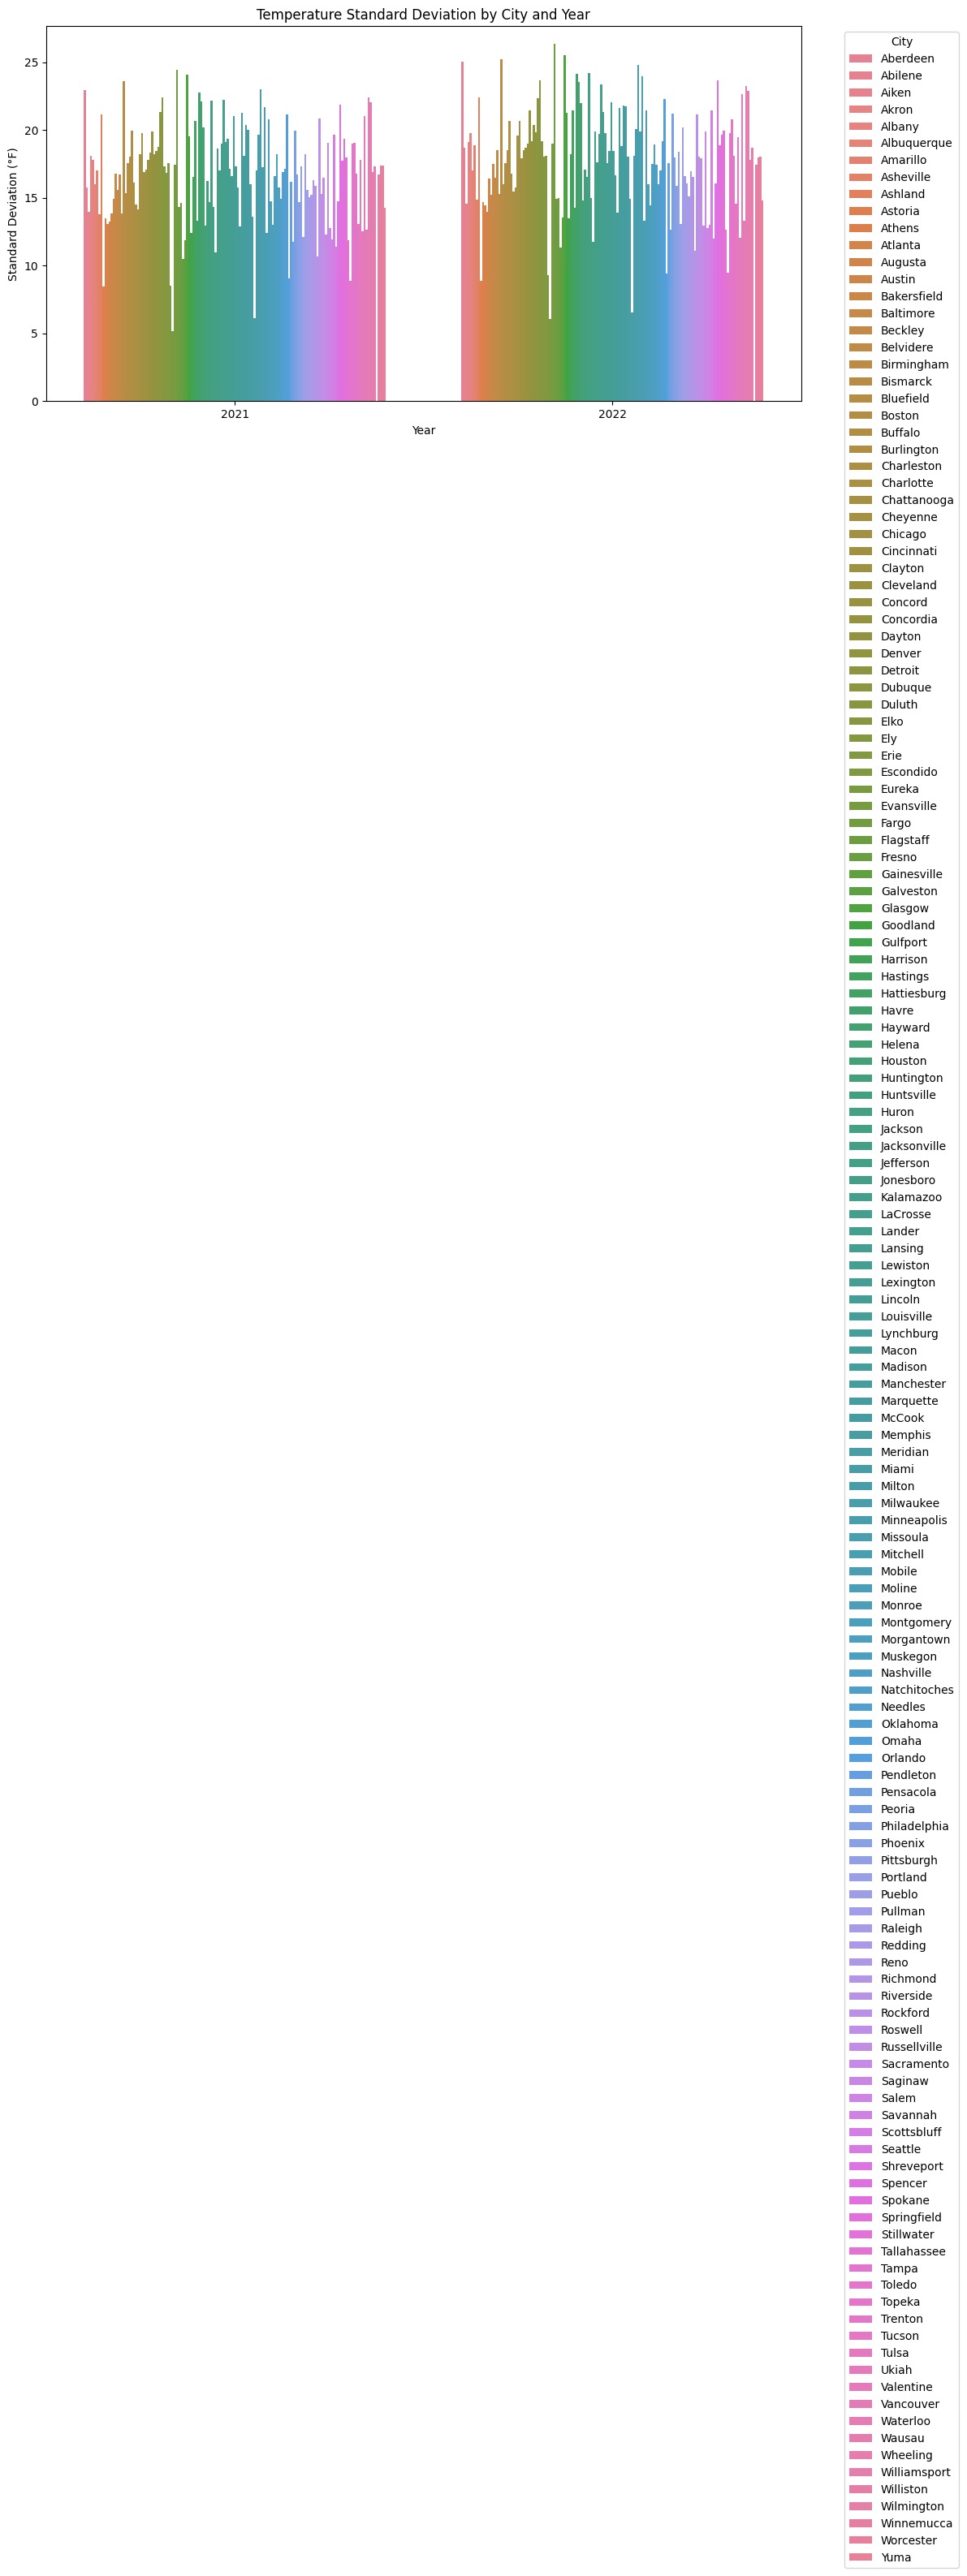

In [13]:
# Graph 1: Temperature Standard Deviation by City and Year
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(data=weather_summary, x='year', y='std dev temp', hue='city name')
plt.title('Temperature Standard Deviation by City and Year')
plt.ylabel('Standard Deviation (°F)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

/var/folders/qf/f6c3h42158l2_2_yd_q6qqnm0000gn/T/ipykernel_17091/3162104495.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


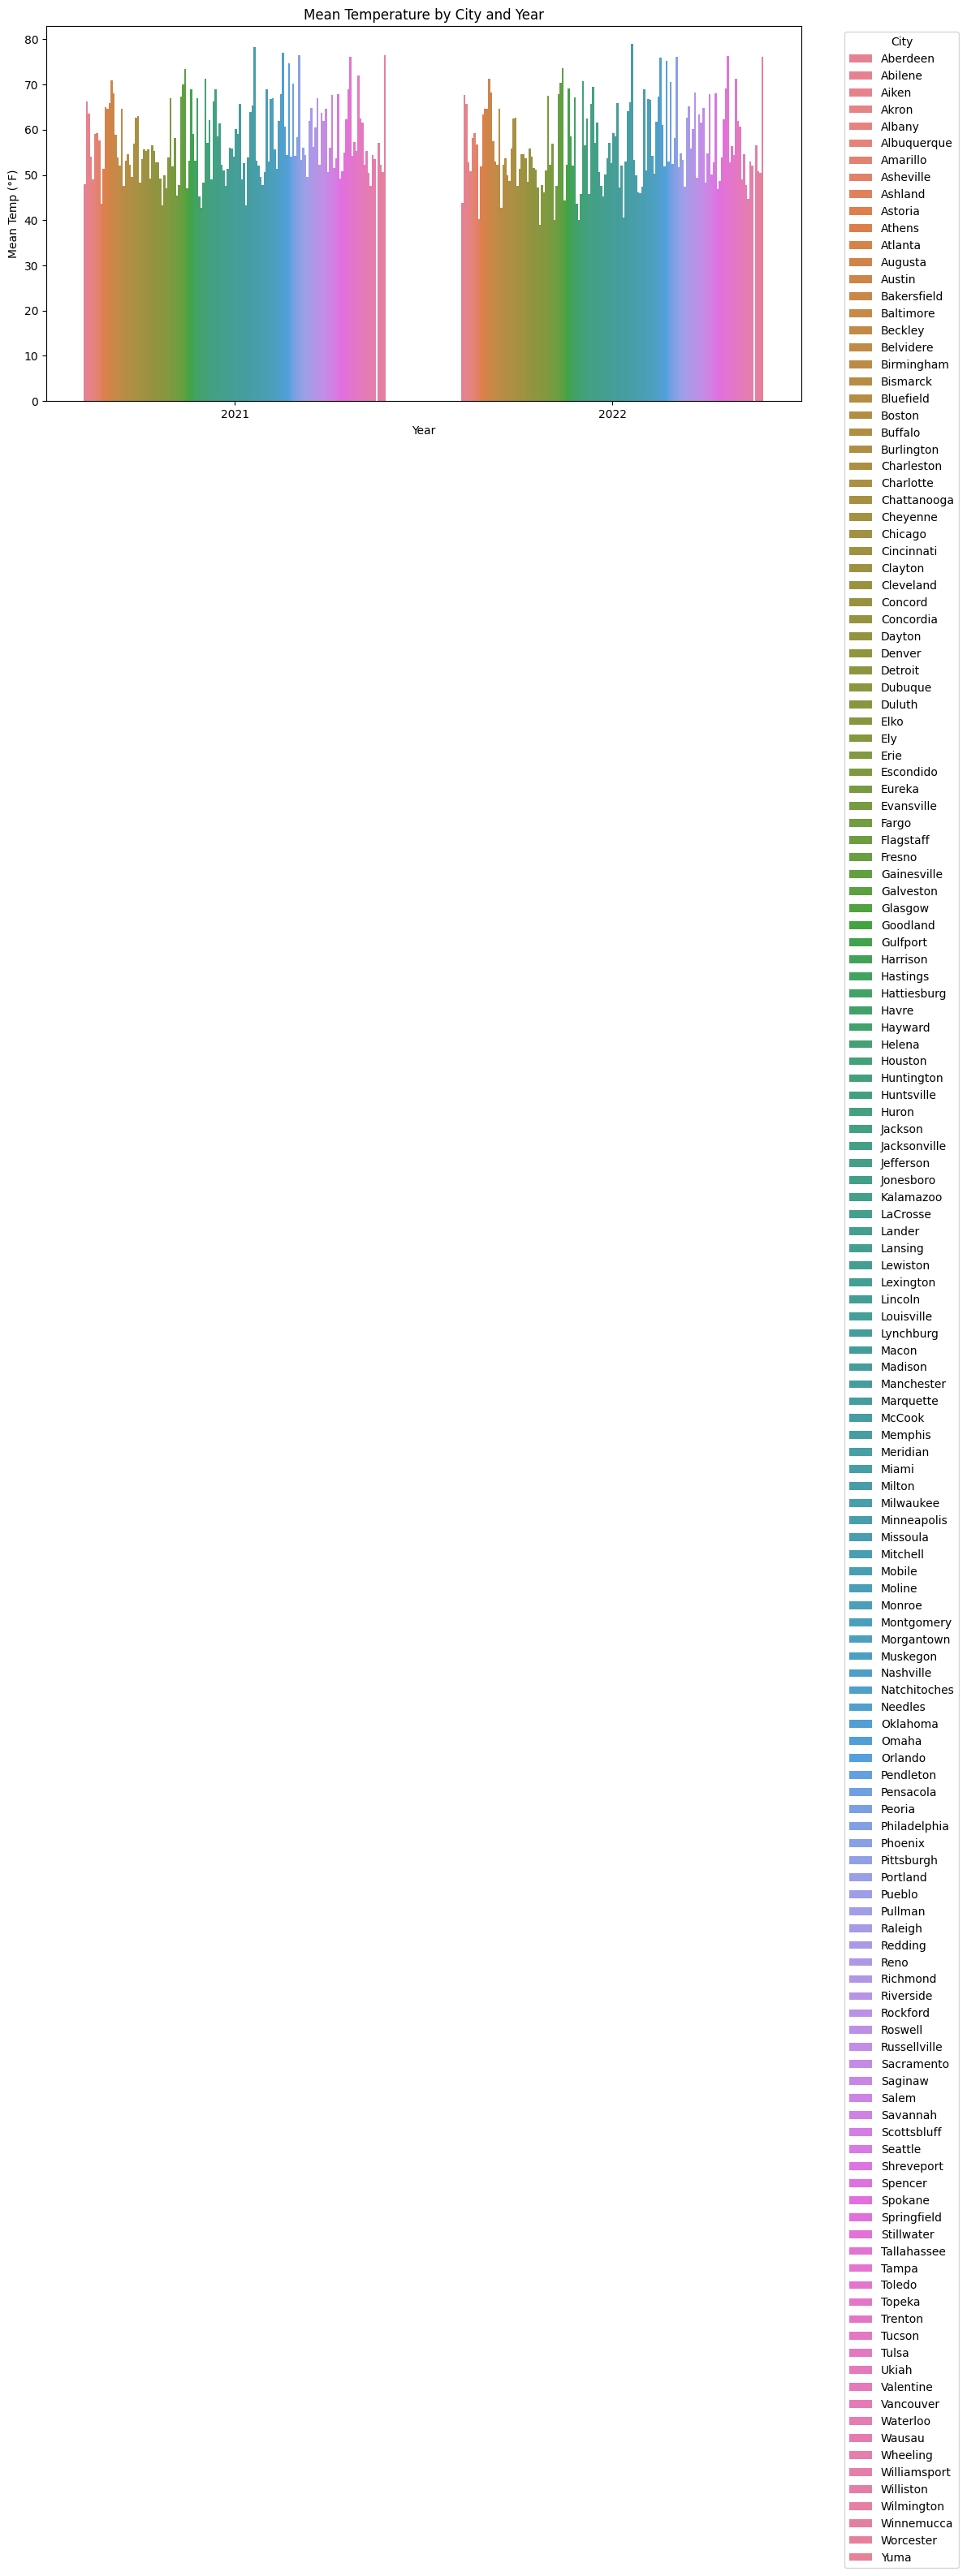

In [14]:
# Graph 2: Mean Temperature by City and Year
plt.figure(figsize=(12, 6))
sns.barplot(data=weather_summary, x='year', y='mean temp', hue='city name')
plt.title('Mean Temperature by City and Year')
plt.ylabel('Mean Temp (°F)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

/var/folders/qf/f6c3h42158l2_2_yd_q6qqnm0000gn/T/ipykernel_17091/3674061777.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


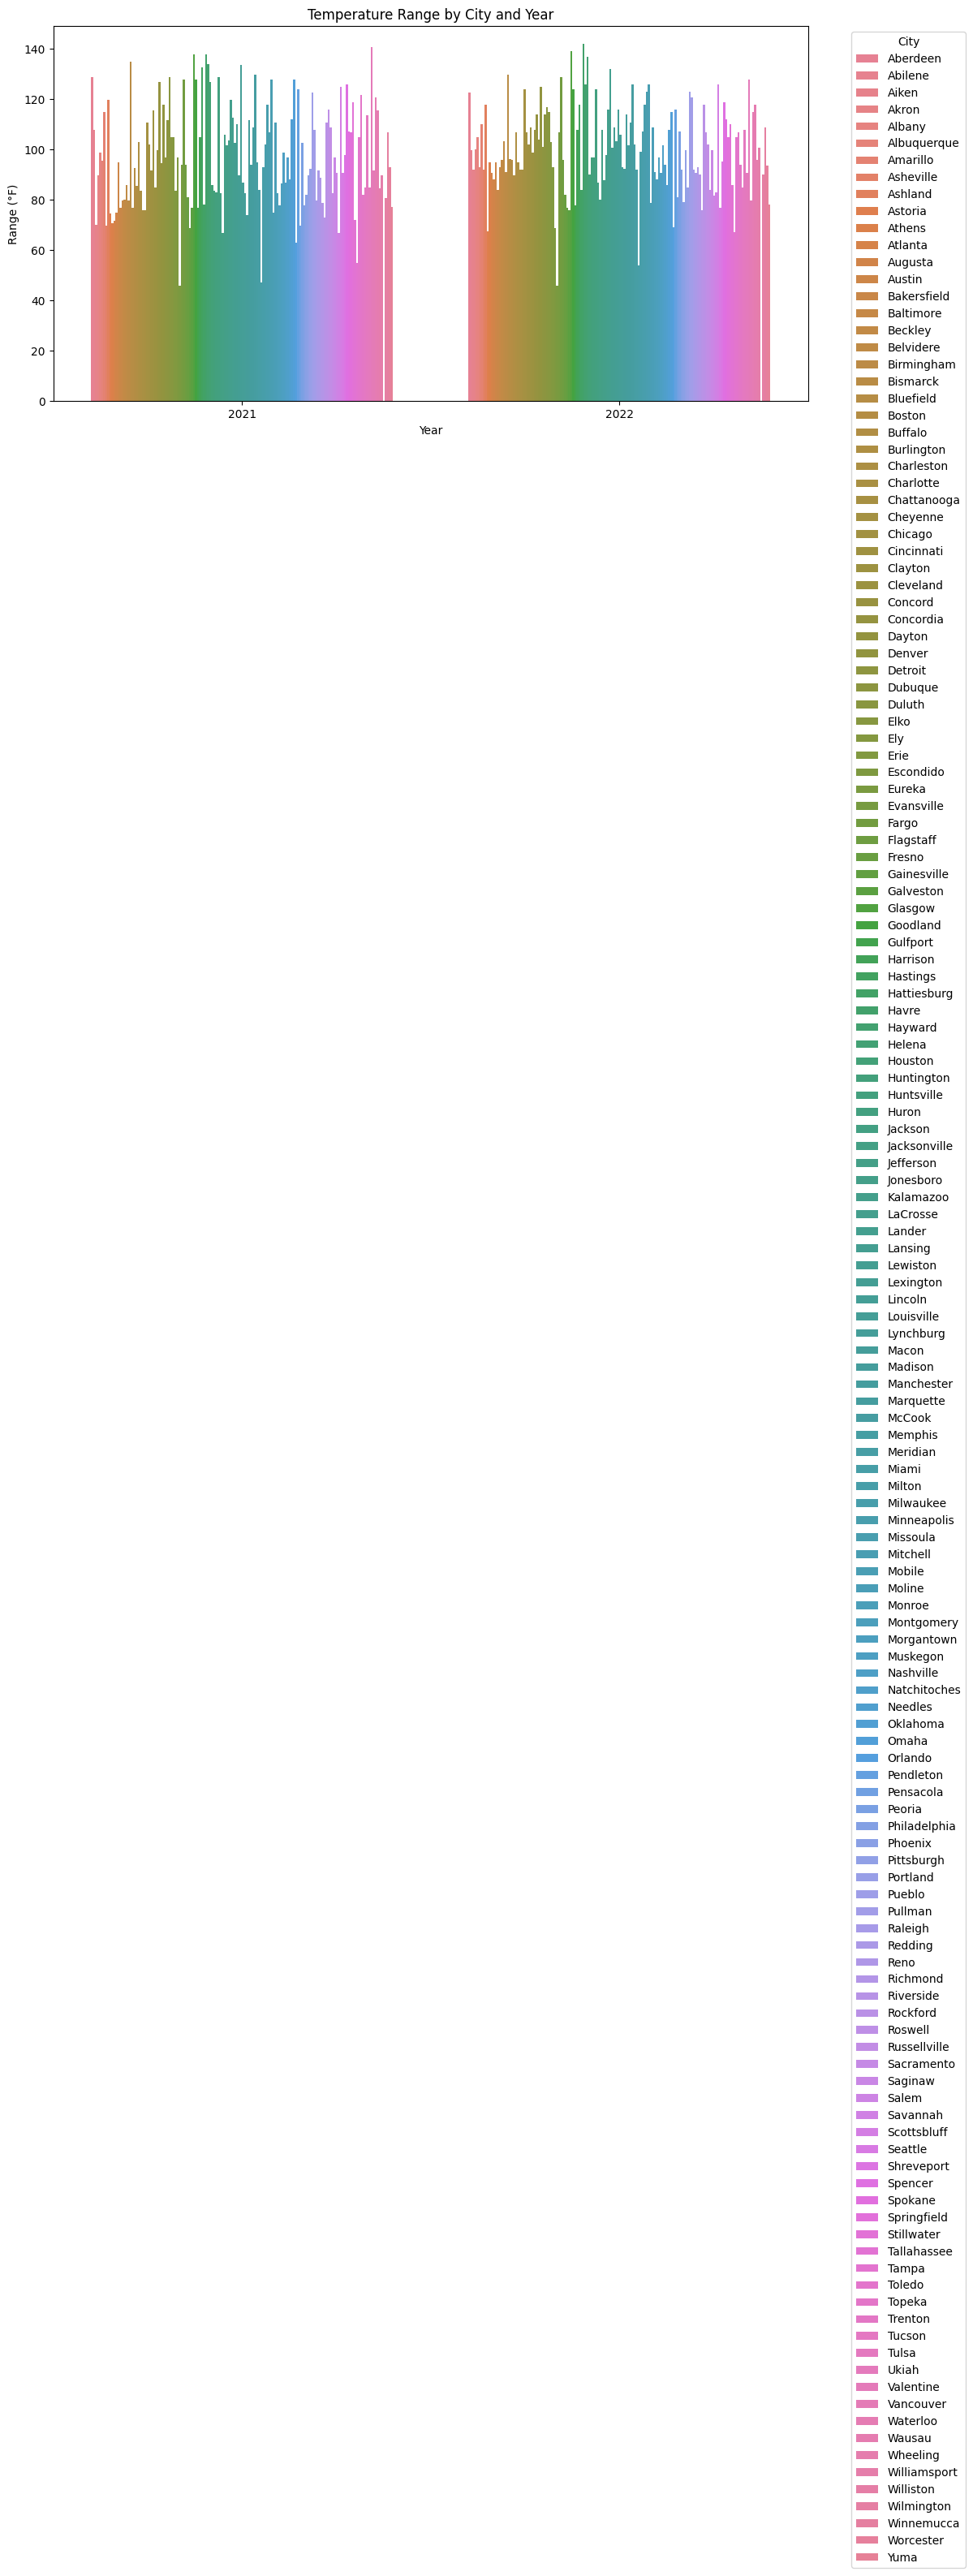

In [15]:
# Graph 3: Temperature Range by City and Year
plt.figure(figsize=(12, 6))
sns.barplot(data=weather_summary, x='year', y='range temp', hue='city name')
plt.title('Temperature Range by City and Year')
plt.ylabel('Range (°F)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 2 - Mental Health vs. Temperature

We will explore the relationship between mental health and temperature metrics across cities. Specifically, we will visualize how rates of frequent mental distress relate to key temperature statistics.

**Steps:**
1. Use the merged dataset `combined_df` which includes both mental health and temperature data.
2. Create scatterplots where:
   - x-axis = `mental distress %` (CDC-reported)
   - y-axis = `std dev temp`
   - hue = `year` (2021 or 2022)
3. Interpret visual trends: do cities with more temperature fluctuation report more mental distress?

### Graph - Mental Distress vs. Temperature Standard Deviation

In [16]:
# Filter to just 'Frequent mental distress among adults'
mh_clean = us_health_data[us_health_data['Measure'] == 'Frequent mental distress among adults']

# Keep only needed columns
mh_clean = mh_clean[['Year', 'LocationName', 'Measure', 'Data_Value']]
mh_clean = mh_clean.rename(columns={
    'Year': 'year',
    'LocationName': 'city name',
    'Data_Value': 'mental distress %'
})

# Convert to numeric
mh_clean['mental distress %'] = pd.to_numeric(mh_clean['mental distress %'], errors='coerce')

# Merge with weather_summary (which has 'city name' and 'year')
combined_df = pd.merge(weather_summary, mh_clean, on=['city name', 'year'])

# Check  
print(combined_df['year'].value_counts())
print("Mental Health years:", mh_clean['year'].unique())
print("Weather years:", weather_summary['year'].unique())
print("Mental Health (2021) cities:", mh_clean[mh_clean['year'] == 2021]['city name'].nunique())
print("Weather (2021) cities:", weather_summary[weather_summary['year'] == 2021]['city name'].nunique())

combined_df.head()

year
2022    1796
Name: count, dtype: int64
Mental Health years: [2022]
Weather years: [2021 2022]
Mental Health (2021) cities: 0
Weather (2021) cities: 148


,city name,year,mean temp,std dev temp,max temp,min temp,range temp,Measure,mental distress %
0,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7,Frequent mental distress among adults,17.2
1,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7,Frequent mental distress among adults,16.7
2,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7,Frequent mental distress among adults,15.8
3,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7,Frequent mental distress among adults,14.3
4,Aberdeen,2022,43.792877,25.022855,100.9,-21.8,122.7,Frequent mental distress among adults,18.5


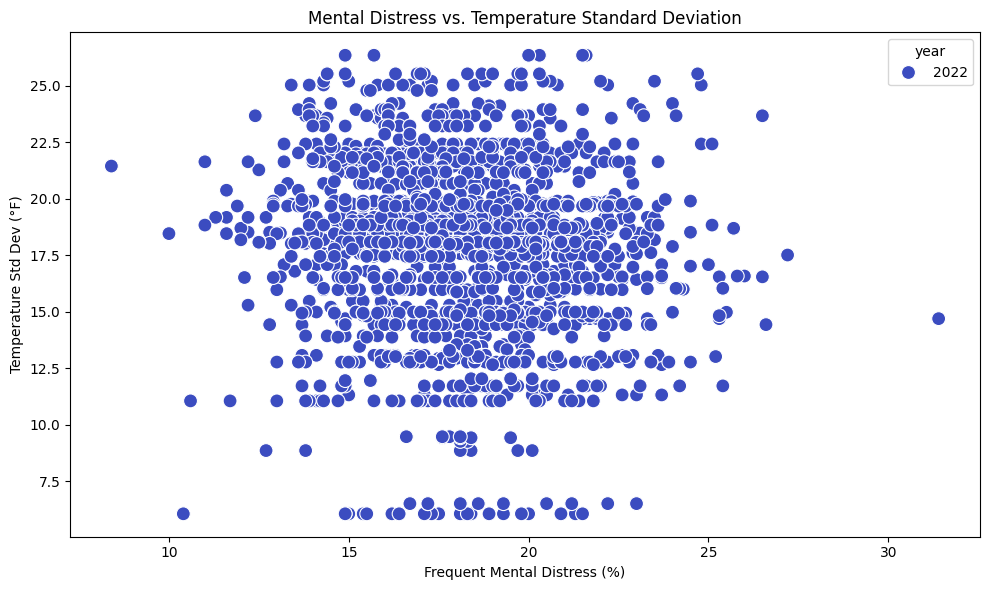

In [17]:
# Graph 2: Mental Distress vs. Temperature Variability (Std Dev)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=combined_df,
    x='mental distress %',
    y='std dev temp',
    hue='year',
    palette='coolwarm',
    s=100
)
plt.title('Mental Distress vs. Temperature Standard Deviation')
plt.xlabel('Frequent Mental Distress (%)')
plt.ylabel('Temperature Std Dev (°F)')
plt.tight_layout()
plt.show()

/var/folders/qf/f6c3h42158l2_2_yd_q6qqnm0000gn/T/ipykernel_17091/1025478076.py:7: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


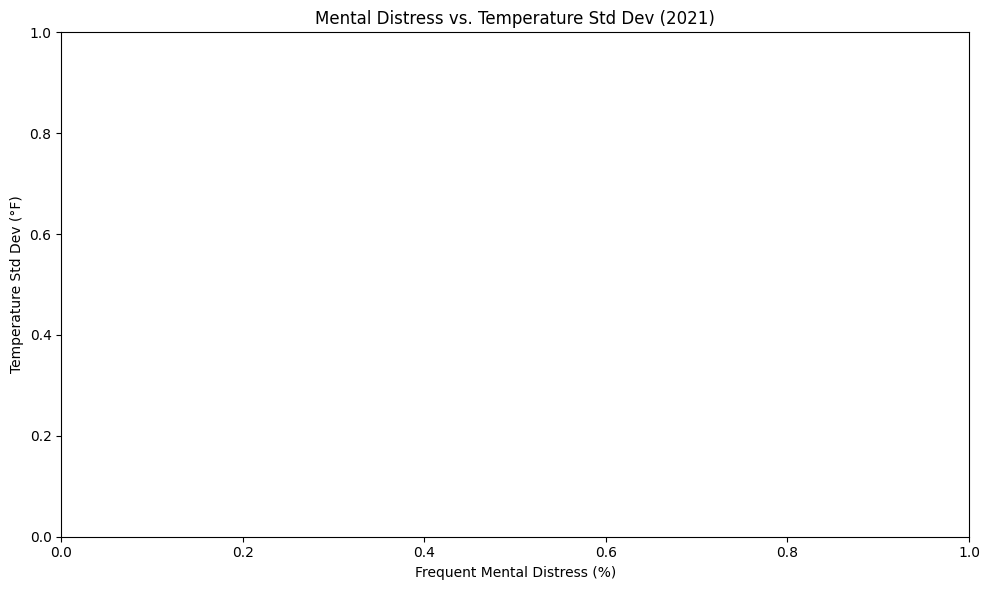

In [18]:
# Graph 2 (2021 Only): Mental Distress vs. Temperature Variability (Std Dev)

# Filter to 2021 only
combined_2021 = combined_df[combined_df['year'] == 2021]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=combined_2021,
    x='mental distress %',
    y='std dev temp',
    hue='year',  # will just be 2021, but keeps legend consistent
    palette='coolwarm',
    s=100
)
plt.title('Mental Distress vs. Temperature Std Dev (2021)')
plt.xlabel('Frequent Mental Distress (%)')
plt.ylabel('Temperature Std Dev (°F)')
plt.tight_layout()
plt.show()

## Second Analysis: Mental Health and Temperature Variability

In this section, we explore whether cities with greater temperature variability experience higher rates of frequent mental distress. We merge cleaned CDC mental health data with temperature statistics (mean, standard deviation, and range). The visual below shows a scatterplot of temperature std dev vs. mental distress.

In [ ]:
## YOUR CODE HERE
## FEEL FREE TO ADD MULTIPLE CELLS PER SECTION

## ETC AD NASEUM

Some more words and stuff.  Remember notebooks work best if you interleave the code that generates a result with properly annotate figures and text that puts these results into context.

In [ ]:
## YOUR CODE HERE
## FEEL FREE TO ADD MULTIPLE CELLS PER SECTION

# Ethics & Privacy

Using publicly available datasets, our project explores the relationship between seasonal temperature variability and mental health outcomes. Given the use of sensitive health information, it is crucial to uphold ethical standards at every stage, from posing the research question to interpreting and sharing our findings.

We acknowledge that mental health is a personal and stigmatized topic. If not approached carefully, our analysis could unintentionally lead to misinterpretations and/or harmful stereotypes. We used datasets from credible public sources. Both the CDC mental health data and the Carnegie Mellon Temperature and Precipitation Data are publicly available to download, with no identifiable personal data. Our weather data is aggregated at the city level and does not contain personally identifiable information, however, it is important to understand that mental health data patterns are shaped by complex social and economic inequalities. In addition, the weather data is based on models and may not include small differences in temperature that people experience. For example, the way shade or buildings can affect how cold or hot it feels in different areas. For this reason, we avoided directly comparing cities and ranking them in terms of being “happier” or “more stable”. Instead, our analysis is framed as an exploration of how environmental factors may affect mental health trends across the United States.

The mental health metrics we use (depression and frequent mental distress) are estimated using a statistical model technique called multilevel regression and poststratification, based on large datasets including the CDC’s Behavioral Risk Factor Surveillance System and U.S. Census data. We recognize that these model-based estimates provide helpful information at the city level, but they are not direct individual-level responses. The dataset does not raise any privacy concerns, however, there are ethical considerations that must be addressed.

The estimates for the CDC mental health data apply only to adults (18 and over), which means that mental health experiences among younger populations are not represented. This introduces bias in cities with a larger youth population. Additionally, the BRFSS is based on survey responses; it is possible that the data gathered may have underrepresented marginalized populations, some individuals unable to submit the survey due to accessibility, language barriers, or disclosure of mental health. Individuals with reliable internet access, literacy skills, and the patience for long surveys are more likely to participate, introducing potential bias. 

We are aware as a group that if not carefully addressed, these factors could lead to skewed interpretations and inaccuracy in our findings. To mitigate these potential biases, we will read through the documentation for both datasets before fully identifying known limitations in data collection, such as underrepresented regions or demographic groups, and also to get a comprehensive understanding of our datasets. We will also assess how surveys were conducted and note any missing data in both datasets (climate records and mental health), especially from less-monitored regions. During our analysis, we will be transparent about how the data is modeled and avoid implying causality. 

We acknowledge that combining weather and mental health data could potentially lead to overgeneralized conclusions. Thus, we will use respectful language around mental health while presenting our findings. Our goal is to responsibly explore how the environment may influence well-being outcomes, without reinforcing stereotypes or spreading misinformation.


# Discussion and Conclusion

Wrap it all up here.  Somewhere between 3 and 10 paragraphs roughly.  A good time to refer back to your Background section and review how this work extended the previous stuff. 


# Team Contributions

Speficy who did what.  This should be pretty granular, perhaps bullet points, no more than a few sentences per person.